In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('data/img2.png')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [34]:
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

_, inverse = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY_INV
)

threshold, otsu = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Selected threshold:", threshold)

adaptive = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2,
)

Selected threshold: 118.0


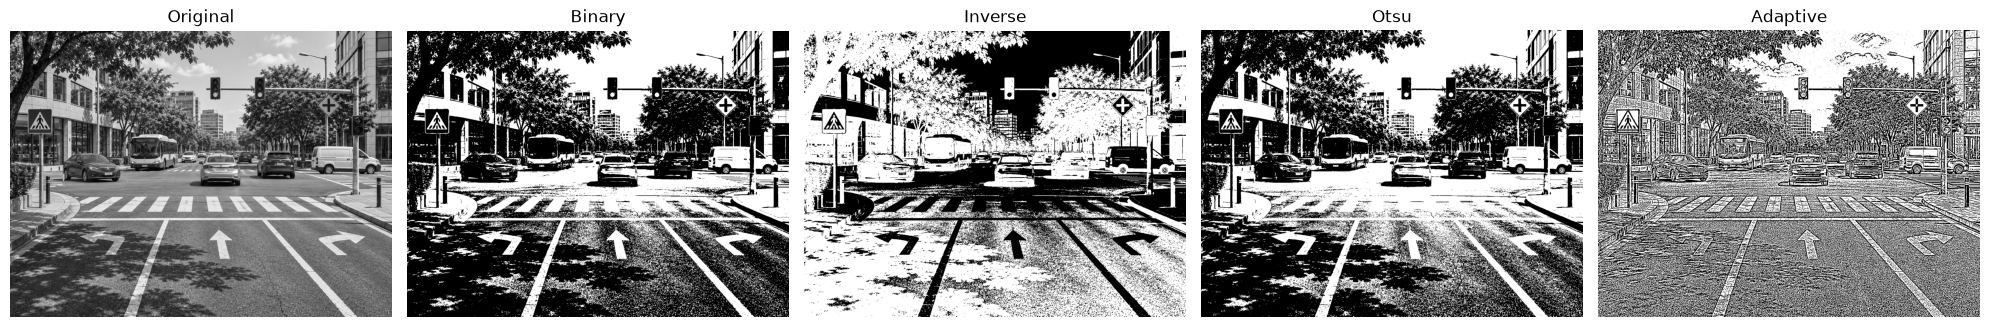

In [35]:
images = [
    ("Original", gray),
    ("Binary", binary),
    ("Inverse", inverse),
    ("Otsu", otsu),
    ("Adaptive", adaptive),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
kernel = np.ones((3, 3), dtype=np.uint8)

eroded = cv2.erode(binary, kernel, iterations=1)

dilated = cv2.dilate(binary, kernel, iterations=1)

opened = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel
)

closed = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel
)

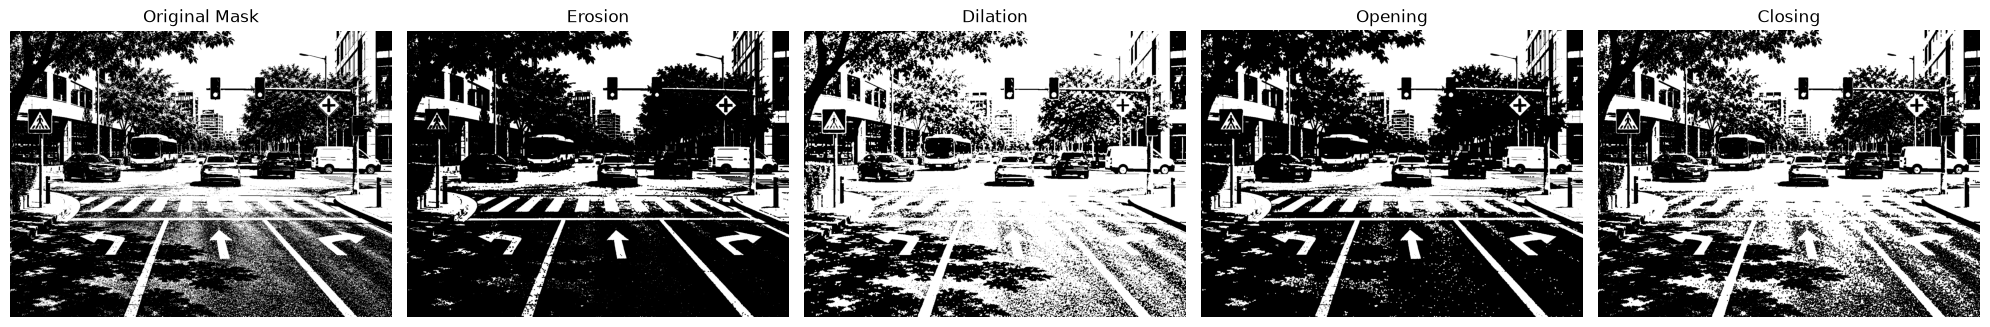

In [37]:
images = [
    ("Original Mask", binary),
    ("Erosion", eroded),
    ("Dilation", dilated),
    ("Opening", opened),
    ("Closing", closed),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

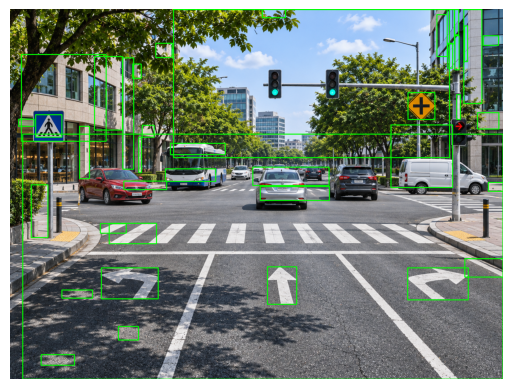

In [38]:
contours, _ = cv2.findContours(
    opened,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE,
)

result = image.copy()
min_area = 500


for contour in contours:

    # Ignore small regions
    if cv2.contourArea(contour) < min_area:
        continue

    # Extract bounding box
    x, y, w, h = cv2.boundingRect(contour)

    # Draw bounding box
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2,
    )

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [39]:
height, width = image.shape[:2]

roi = image[height // 2:, :]

In [40]:
height, width = image.shape[:2]

# Define road boundaries
points = np.array([
    [int(width * 0.05), height - 1],
    [int(width * 0.40), int(height * 0.45)],
    [int(width * 0.60), int(height * 0.45)],
    [int(width * 0.95), height - 1],
], dtype=np.int32)

# Create an empty mask
mask = np.zeros((height, width), dtype=np.uint8)

# Fill the selected region
cv2.fillPoly(mask, [points], 255)

# Apply the mask
roi = cv2.bitwise_and(image, image, mask=mask)

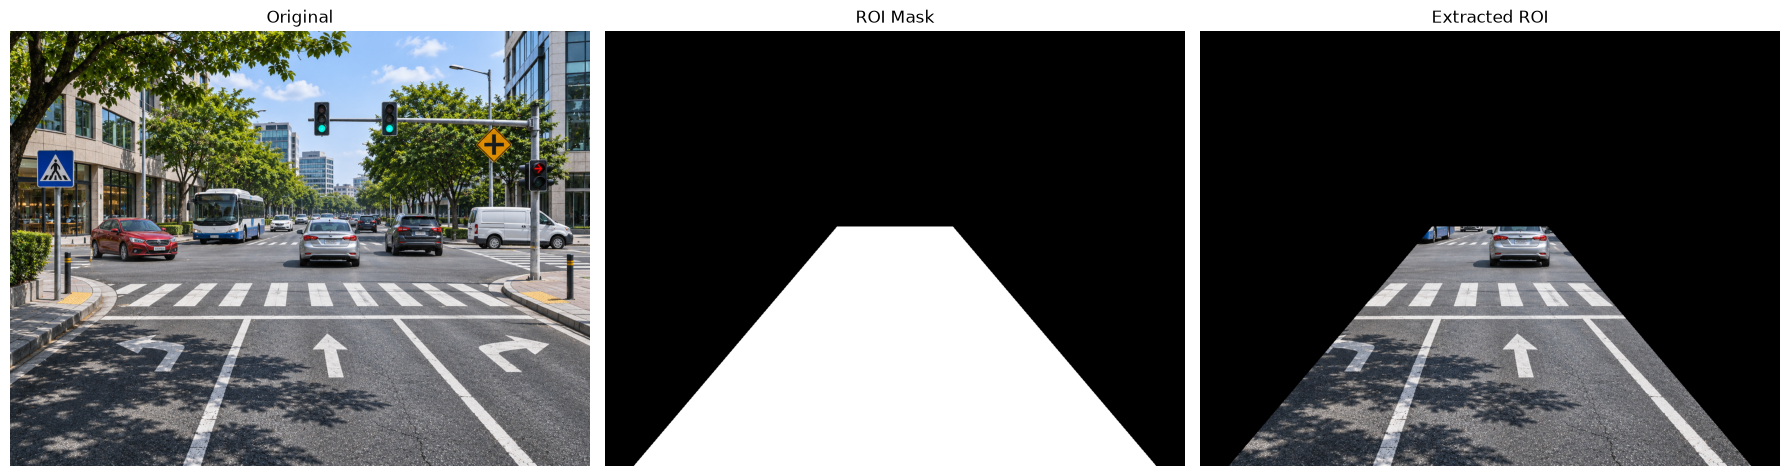

In [42]:
images = [
    ("Original", cv2.cvtColor(image, cv2.COLOR_BGR2RGB)),
    ("ROI Mask", mask),
    ("Extracted ROI", cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

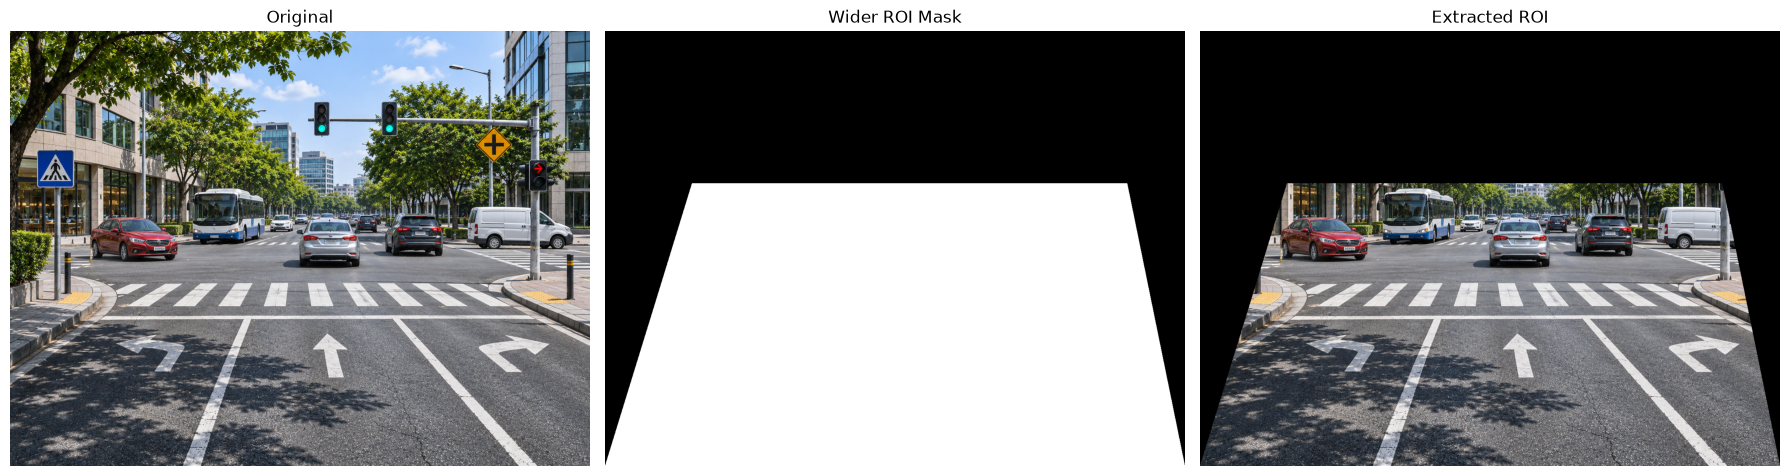

In [50]:
height, width = image.shape[:2]

# Define a wider road ROI
points = np.array([
    [0, height - 1],
    [int(width * 0.15), int(height * 0.35)],
    [int(width * 0.90), int(height * 0.35)],
    [width - 1, height - 1],
], dtype=np.int32)

mask = np.zeros((height, width), dtype=np.uint8)

cv2.fillPoly(mask, [points], 255)

roi = cv2.bitwise_and(image, image, mask=mask)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [
    ("Original", cv2.cvtColor(image, cv2.COLOR_BGR2RGB)),
    ("Wider ROI Mask", mask),
    ("Extracted ROI", cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)),
]

for ax, (title, img) in zip(axes, images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()